# NN_L12_prompt_sensitivity

**Macro-F1 of zero-shot Qwen2.5-1.5B and 3B under five paraphrases of the same instruction, on Financial PhraseBank and Twitter financial news: the range is a measure of prompt risk.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_prompt_sensitivity/NN_L12_prompt_sensitivity.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

pb 1.5B: range over the 5 wordings = 14.2   [sens.pb_15B.range]
pb 3B: range over the 5 wordings = 3.6   [sens.pb_3B.range]
tw 1.5B: range over the 5 wordings = 13.3   [sens.tw_15B.range]
tw 3B: range over the 5 wordings = 12.9   [sens.tw_3B.range]


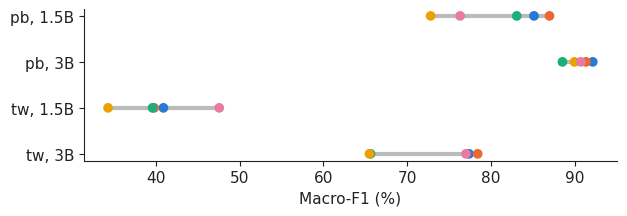

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
from sklearn.metrics import f1_score, accuracy_score
LAB = {'pb': ['positive', 'negative', 'neutral'], 'tw': ['bullish', 'bearish', 'neutral']}
def f1(y, p, ds):
    return f1_score(y, p, labels=LAB[ds], average='macro')
def pred(df, m, ds):
    P = df[[f'{m}_{l}' for l in LAB[ds]]].values
    return [LAB[ds][i] for i in P.argmax(1)]
rows = []
for ds in ('pb', 'tw'):
    L = pd.read_csv(RES + f'sensitivity_labels_{ds}.csv')
    for s in ('1.5B', '3B'):
        v = [100 * f1(L.label, L[f'{s}_i{i}'], ds) for i in range(1, 6)]
        rows.append((ds, s, v))
        show(f'sens.{ds}_' + s.replace('.', '') + '.range', f'{ds} {s}: range over the 5 wordings', round(max(v) - min(v), 1))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
for r, (ds, s, v) in enumerate(rows):
    ax.plot([min(v), max(v)], [r, r], color='#bbbbbb', lw=3)
    ax.scatter(v, [r] * 5, color=SERIES[:5], zorder=3)
ax.set_yticks(range(4))
ax.set_yticklabels([f'{d}, {s}' for d, s, _ in rows])
ax.invert_yaxis()
ax.set_xlabel('Macro-F1 (%)')
fig.tight_layout()
fig.savefig('prompt_sensitivity.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()